In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2
from pathlib import Path

# Tìm thư mục images/ từ thư mục đang chạy trở lên (chạy từ lam_viec/ hay gốc repo đều được)
IMG_DIR = next(p / "images" for p in [Path.cwd(), *Path.cwd().parents] if (p / "images").is_dir())

## Hồng Gấm – Demo 1: Ảnh là bảng số

In [ ]:
img = cv2.imread(str(IMG_DIR / "baboon.jpg"))

if img is None:
    raise FileNotFoundError("Không tìm thấy baboon.jpg")

img = cv2.resize(img, (200, 200))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.xlabel("Original Image", fontsize=12, fontweight="bold")
plt.xticks([])
plt.yticks([])
plt.show()

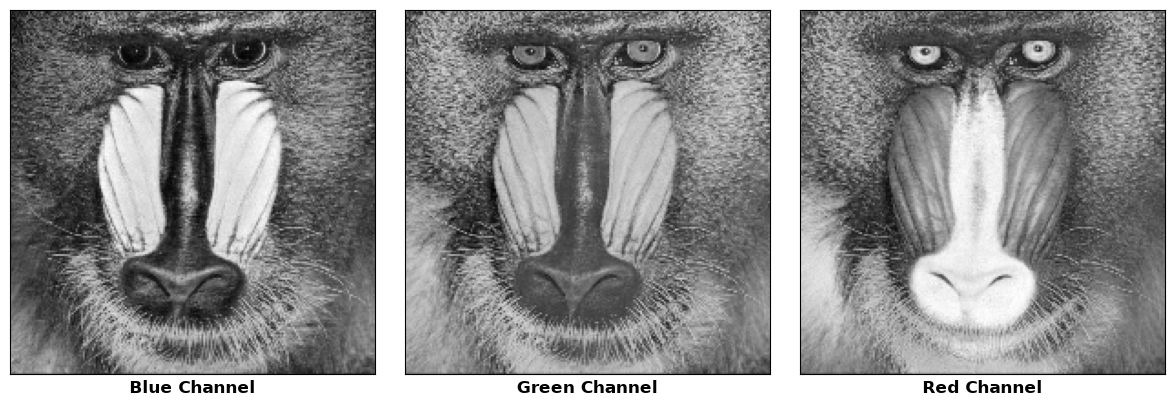

In [73]:
B, G, R = cv2.split(img)

channels = [B, G, R]
labels = ["Blue Channel", "Green Channel", "Red Channel"]

plt.figure(figsize=(12, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(channels[i], cmap="gray", vmin=0, vmax=255)
    plt.xlabel(labels[i], fontsize=12, fontweight="bold")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

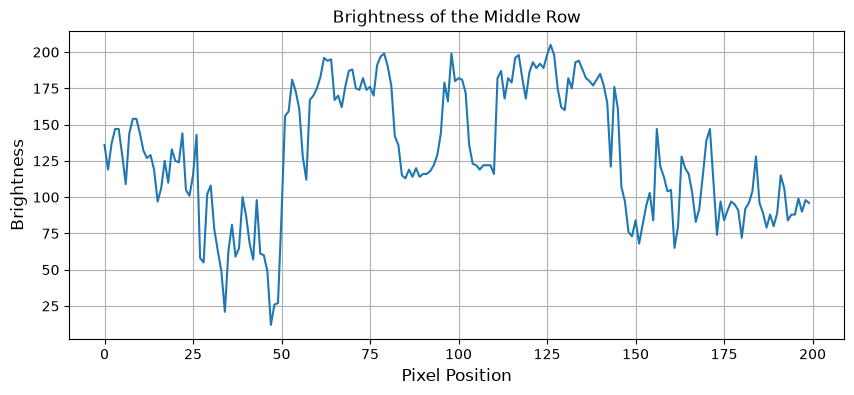

In [74]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

row = gray.shape[0] // 2

plt.figure(figsize=(10, 4))
plt.plot(gray[row, :])

plt.xlabel("Pixel Position", fontsize=12)
plt.ylabel("Brightness", fontsize=12)
plt.title("Brightness of the Middle Row")

plt.grid(True)
plt.show()

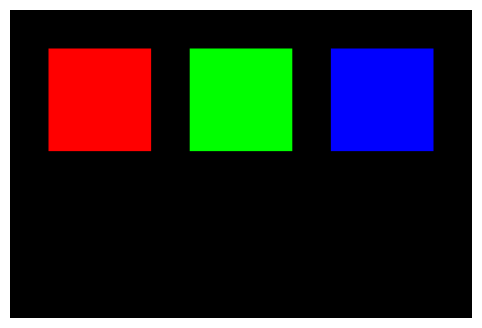

In [75]:

color_img = np.zeros((240, 360, 3), dtype=np.uint8)

color_img[30:110, 30:110] = (0, 0, 255)
color_img[30:110, 140:220] = (0, 255, 0)
color_img[30:110, 250:330] = (255, 0, 0)

plt.figure(figsize=(8, 4))
plt.imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

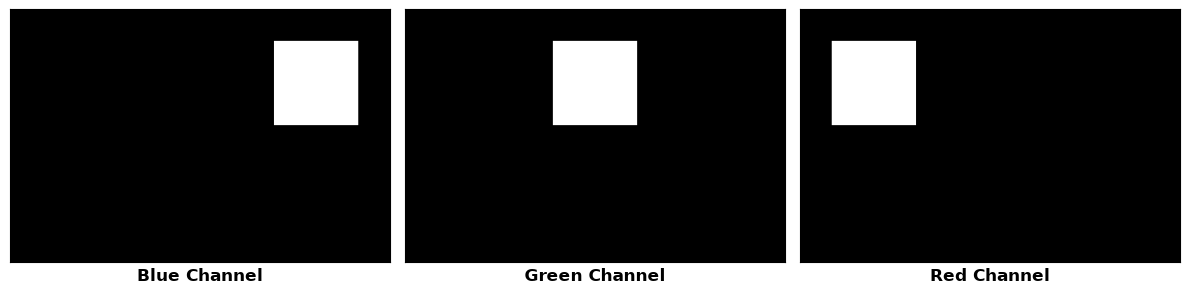

In [76]:

cB, cG, cR = cv2.split(color_img)

plt.figure(figsize=(12, 3))

for i, (ch, label) in enumerate(zip([cB, cG, cR], ["Blue Channel", "Green Channel", "Red Channel"])):
    plt.subplot(1, 3, i + 1)
    plt.imshow(ch, cmap="gray", vmin=0, vmax=255)
    plt.xlabel(label, fontsize=12, fontweight="bold")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

## Demo 3a: convolve2d, lọc hộp, Gaussian

In [77]:
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

In [78]:

test_image = np.arange(1, 26, dtype=np.float64).reshape(5, 5)

test_kernel = np.array([
    [1, 2, 3],
    [0, 4, 5],
    [6, 7, 8]
], dtype=np.float64) / 36

border_types = {
    "constant": cv2.BORDER_CONSTANT,
    "reflect": cv2.BORDER_REFLECT_101,
    "edge": cv2.BORDER_REPLICATE
}

for padding, border in border_types.items():
    custom_result = convolve2d(
        test_image,
        test_kernel,
        padding
    )

    opencv_result = cv2.filter2D(
        test_image,
        ddepth=-1,
        kernel=np.flip(test_kernel, axis=(0, 1)),
        borderType=border
    )

    max_error = np.max(
        np.abs(custom_result - opencv_result)
    )

    print(f"{padding}: max error = {max_error:.12f}")

constant: max error = 0.000000000000
reflect: max error = 0.000000000000
edge: max error = 0.000000000000


In [ ]:
# Ảnh có biến đổi ngay sát mép: hàng/cột ở mép khác hẳn hàng/cột kế bên,
# nên reflect (lấy đối xứng bỏ qua pixel mép) và edge (lặp lại pixel mép) cho kết quả khác nhau
test_img = np.zeros((30, 30), dtype=np.float64)
test_img[0, :] = 255                                   # vạch sáng nằm đúng hàng mép trên
test_img[:, 0] = 255                                   # vạch sáng nằm đúng cột mép trái
test_img[:, 20:] = np.linspace(0, 255, 10)             # dải sáng dần ra mép phải
test_img[15:25, 8:16] = 120

kernel = np.ones((9, 9), dtype=np.float64) / 81

results = {
    mode: convolve2d(test_img, kernel, mode)
    for mode in ("constant", "reflect", "edge")
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

axes[0, 0].imshow(test_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

diff = np.abs(results["reflect"] - results["edge"])
im = axes[1, 0].imshow(diff, cmap="magma", interpolation="nearest")
axes[1, 0].set_title(f"|reflect - edge| (max = {diff.max():.1f})")
axes[1, 0].axis("off")
fig.colorbar(im, ax=axes[1, 0], fraction=0.046)

for col, (mode, result) in enumerate(results.items(), 1):
    axes[0, col].imshow(
        result,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[0, col].set_title(f"Padding: {mode}")
    axes[0, col].axis("off")

    axes[1, col].imshow(
        result[:12, :12],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    axes[1, col].set_title(f"{mode} - Zoom")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

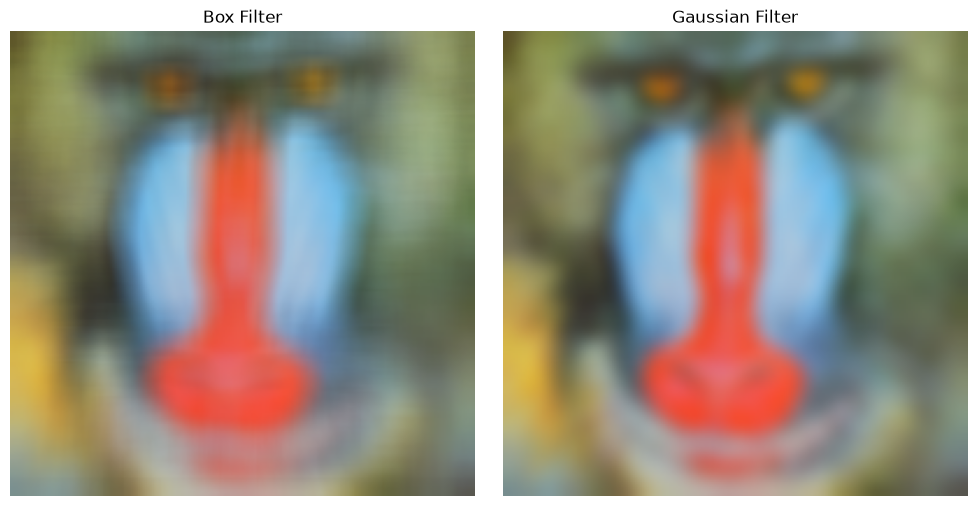

In [80]:

box_kernel = np.ones((15, 15), dtype=np.float64) / 225

g = cv2.getGaussianKernel(15, 4)
gaussian_kernel = g @ g.T

box_channels = [
    convolve2d(img[:, :, c], box_kernel, "reflect")
    for c in range(3)
]

gaussian_channels = [
    convolve2d(img[:, :, c], gaussian_kernel, "reflect")
    for c in range(3)
]

box_blur = np.clip(
    np.round(cv2.merge(box_channels)), 0, 255
).astype(np.uint8)

gaussian_blur = np.clip(
    np.round(cv2.merge(gaussian_channels)), 0, 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(box_blur, cv2.COLOR_BGR2RGB))
axes[0].set_title("Box Filter")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(gaussian_blur, cv2.COLOR_BGR2RGB))
axes[1].set_title("Gaussian Filter")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [81]:

opencv_box = cv2.blur(img, (15, 15), borderType=cv2.BORDER_REFLECT_101)
opencv_gaussian = cv2.GaussianBlur(img, (15, 15), 4, borderType=cv2.BORDER_REFLECT_101)

box_error = np.max(np.abs(box_blur.astype(int) - opencv_box.astype(int)))
gaussian_error = np.max(np.abs(gaussian_blur.astype(int) - opencv_gaussian.astype(int)))

print(f"Box filter vs cv2.blur: max error = {box_error}")
print(f"Gaussian vs cv2.GaussianBlur: max error = {gaussian_error}")

Box filter vs cv2.blur: max error = 0
Gaussian vs cv2.GaussianBlur: max error = 1


In [ ]:
cv2.imwrite(str(IMG_DIR / "box_blur.jpg"), box_blur)
cv2.imwrite(str(IMG_DIR / "gaussian_blur.jpg"), gaussian_blur)

## KT3 – Thí nghiệm Hough

In [ ]:
def create_line_image(segments, size=400):
    image = np.zeros((size, size), dtype=np.uint8)
    answers = []

    for rho0, theta0, length in segments:
        theta = np.deg2rad(theta0)

        normal = np.array([np.cos(theta), np.sin(theta)])
        direction = np.array([-np.sin(theta), np.cos(theta)])

        center = normal * rho0
        # Lấy tâm đoạn là giao điểm với đường giữa ảnh: y = size/2 nếu đường gần dọc,
        # x = size/2 nếu đường gần ngang (tránh chia cho 0 khi theta = 90°)
        if abs(direction[1]) >= abs(direction[0]):
            center = center + direction * (size / 2 - center[1]) / direction[1]
        else:
            center = center + direction * (size / 2 - center[0]) / direction[0]

        p1 = center - direction * length / 2
        p2 = center + direction * length / 2

        if np.any(p1 < 0) or np.any(p1 >= size) or np.any(p2 < 0) or np.any(p2 >= size):
            raise ValueError("Đoạn thẳng nằm ngoài ảnh")

        shift = 8
        scale = 1 << shift

        pt1 = tuple(np.rint(p1 * scale).astype(int))
        pt2 = tuple(np.rint(p2 * scale).astype(int))

        cv2.line(image, pt1, pt2, 255, 1, cv2.LINE_8, shift)

        answers.append((rho0, theta0, length))

    return image, answers

In [ ]:
# Kiểm tra đường ngang: pháp tuyến 90° (y = 200), dài 20 px
horizontal_image, _ = create_line_image([(200, 90, 20)])
ys, xs = np.nonzero(horizontal_image)
print(f"Số pixel: {len(xs)}, y thuộc [{ys.min()}, {ys.max()}], x thuộc [{xs.min()}, {xs.max()}]")

In [ ]:
segments = [
    (110, 3, 300),
    (270, 3, 20)
]

hough_image, answers = create_line_image(segments)

cv2.imwrite(str(IMG_DIR / "hough_test.png"), hough_image)

plt.figure(figsize=(6, 6))
plt.imshow(hough_image, cmap="gray", vmin=0, vmax=255)
plt.title("Hough Test - Long and Short Lines")
plt.axis("off")
plt.show()

for i, (rho, theta, length) in enumerate(answers, 1):
    print(f"Đoạn {i}: rho = {rho}, theta = {theta}°, length = {length}px")

In [ ]:
angle_tests = [
    (200, 0.5, 300),
    (-200, 179.5, 300)
]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (rho, theta, length) in zip(axes, angle_tests):
    image, answer = create_line_image([(rho, theta, length)])

    filename = f"hough_angle_{str(theta).replace('.', '_')}.png"
    cv2.imwrite(str(IMG_DIR / filename), image)

    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"rho={rho}, theta={theta}°")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [86]:
def angle_error(theta_true, theta_detected):
    difference = abs(theta_true - theta_detected) % 180
    return min(difference, 180 - difference)


def rho_error(rho_true, theta_true, rho_detected, theta_detected):
    t1 = np.deg2rad(theta_true)
    t2 = np.deg2rad(theta_detected)

    n1 = np.array([np.cos(t1), np.sin(t1)])
    n2 = np.array([np.cos(t2), np.sin(t2)])

    if np.dot(n1, n2) < 0:
        rho_detected = -rho_detected

    return abs(rho_true - rho_detected)


print("Sai số góc 3° và 5°:", angle_error(3, 5))
print("Sai số góc 0.5° và 179.5°:", angle_error(0.5, 179.5))
print("Sai số rho khi quấn vòng:", rho_error(200, 0.5, -200, 180.5))

Sai số góc 3° và 5°: 2
Sai số góc 0.5° và 179.5°: 1.0
Sai số rho khi quấn vòng: 0


### Hàm Hough dùng chung của nhóm

Ba ô `hough_accumulate`, `find_peaks`, `hough_multiscale` là bản sao từ phần Hough chung của nhóm, giữ nguyên để chạy thí nghiệm. Khi gộp vào `bai_tap.ipynb` chỉ giữ một bản.

In [87]:
def hough_accumulate(edges, theta_range=(0, np.pi), rho_range=None,
                     n_theta=180, n_rho=None, grad_dir=None, delta_deg=None):
    """Bỏ phiếu vào mảng tích lũy. Nếu grad_dir khác None, chỉ bỏ phiếu
    trong dải +/- delta_deg (độ) quanh hướng gradient.
    Trả về (A, thetas, rhos), A có kích thước (n_rho, n_theta)."""
    edges = np.asarray(edges)
    if edges.ndim != 2:
        raise ValueError("edges phải là ảnh hai chiều")

    h, w = edges.shape
    ys, xs = np.nonzero(edges)

    # Trục theta: n_theta giá trị cách đều trong [theta_min, theta_max)
    theta_min, theta_max = theta_range
    if int(n_theta) != n_theta or n_theta < 1 or not theta_min < theta_max:
        raise ValueError("theta_range, n_theta không hợp lệ")
    n_theta = int(n_theta)
    thetas = theta_min + np.arange(n_theta) * (theta_max - theta_min) / n_theta

    # Trục rho: mặc định [-D, D] với D = đường chéo ảnh, bước 1 px
    if rho_range is None:
        D = np.ceil(np.hypot(h - 1, w - 1))
        rho_range = (-D, D)
    rho_min, rho_max = rho_range
    if n_rho is None:
        n_rho = int(round(rho_max - rho_min)) + 1
    if int(n_rho) != n_rho or n_rho < 2 or not rho_min < rho_max:
        raise ValueError("rho_range, n_rho không hợp lệ")
    n_rho = int(n_rho)
    rhos = np.linspace(rho_min, rho_max, n_rho)
    rho_step = (rho_max - rho_min) / (n_rho - 1)

    if grad_dir is not None:
        grad_dir = np.asarray(grad_dir, dtype=np.float64)
        if grad_dir.shape != edges.shape:
            raise ValueError("grad_dir phải cùng kích thước với edges")
        if delta_deg is None:
            delta_deg = 15.0   # tài liệu gợi ý 5°–15°
        if not 0 < delta_deg <= 90:
            raise ValueError("delta_deg phải thuộc (0, 90] độ")
        # Hướng pháp tuyến chỉ có nghĩa theo modulo 180°
        g = grad_dir[ys, xs] % np.pi
        delta = np.deg2rad(delta_deg)

    A = np.zeros((n_rho, n_theta), dtype=np.int64)

    # Với mỗi theta, mọi điểm cạnh cùng bỏ phiếu cho ô rho của mình
    for j, theta in enumerate(thetas):
        rho = xs * np.cos(theta) + ys * np.sin(theta)
        idx = np.rint((rho - rho_min) / rho_step).astype(int)
        hop_le = (idx >= 0) & (idx < n_rho)

        if grad_dir is not None:
            lech = np.abs((g - theta + np.pi / 2) % np.pi - np.pi / 2)
            hop_le &= lech <= delta

        A[:, j] = np.bincount(idx[hop_le], minlength=n_rho)

    return A, thetas, rhos

### Ô đối chiếu thư viện (mục 4.6)

Ô dưới dùng `cv2.HoughLines` **chỉ để kiểm chứng bộ ảnh thử** (đáp án rho, theta của ảnh tạo ra là đúng).
Đây **không phải** kết quả của thuật toán tự viết; kết quả tự viết nằm ở các ô dùng `hough_accumulate`, `find_peaks`, `hough_multiscale` bên dưới.

In [ ]:
# ĐỐI CHIẾU THƯ VIỆN: cv2.HoughLines chỉ dùng để kiểm chứng ảnh thử, không phải thuật toán tự viết
def check_hough_opencv(image, rho_true, theta_true, threshold):
    lines = cv2.HoughLines(image, 1, np.pi / 360, threshold)

    if lines is None:
        print("[OpenCV] Không phát hiện được đường thẳng")
        return

    rho_detected, theta = lines[0][0]
    theta_detected = np.rad2deg(theta)

    e_theta = angle_error(theta_true, theta_detected)
    e_rho = rho_error(rho_true, theta_true, rho_detected, theta_detected)

    print(f"Đáp án: rho={rho_true}, theta={theta_true}°")
    print(f"[OpenCV] Phát hiện: rho={rho_detected:.2f}, theta={theta_detected:.2f}°")
    print(f"[OpenCV] Sai số góc: {e_theta:.2f}°")
    print(f"[OpenCV] Sai số rho: {e_rho:.2f}px")


for rho, theta, length in angle_tests:
    image, _ = create_line_image([(rho, theta, length)])
    print(f"\nĐối chiếu OpenCV, theta={theta}°")
    check_hough_opencv(image, rho, theta, 100)

In [89]:
def smooth_accumulator(A, smooth_sigma=1.0):
    """Làm mờ bảng phiếu theo trục rho bằng kernel Gauss 1 chiều."""
    A = np.asarray(A, dtype=np.float64)
    if smooth_sigma <= 0:
        return A.copy()
    r = int(np.ceil(3 * smooth_sigma))
    x = np.arange(-r, r + 1)
    kernel = np.exp(-x**2 / (2 * smooth_sigma**2))
    kernel = (kernel / kernel.sum())[:, None]   # cột (2r+1) x 1: chỉ làm mờ theo rho
    return convolve2d(A, kernel, padding="constant")


def find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0,
               thetas=None, rhos=None, threshold=0):
    """Làm mượt A bằng convolve2d của nhóm (Gauss theo trục rho, smooth_sigma
    tính bằng ô), triệt phi cực đại, trả về danh sách (rho, theta, votes) sắp
    giảm dần. votes là điểm tích lũy trên bảng đã làm mờ; smooth_sigma=0 thì
    votes là số phiếu gốc. Không truyền thetas, rhos thì rho, theta là chỉ số ô."""
    A = np.asarray(A)
    if A.ndim != 2:
        raise ValueError("A phải là mảng hai chiều")
    if int(n_peaks) != n_peaks or n_peaks < 1:
        raise ValueError("n_peaks phải là số nguyên dương")
    if int(nms_radius) != nms_radius or nms_radius < 0:
        raise ValueError("nms_radius phải là số nguyên không âm")
    nms_radius = int(nms_radius)
    if (thetas is None) != (rhos is None):
        raise ValueError("Phải truyền cả thetas và rhos, hoặc không truyền cả hai")
    if thetas is not None:
        thetas, rhos = np.asarray(thetas), np.asarray(rhos)
        if A.shape != (len(rhos), len(thetas)):
            raise ValueError("A phải có kích thước (len(rhos), len(thetas))")

    # Không làm mờ theo theta: kéo đỉnh của đoạn ngắn lệch góc (xem kiểm thử bên dưới)
    S = smooth_accumulator(A, smooth_sigma)
    n_rho, n_theta = S.shape

    # Chỉ quấn vòng theta khi lưới phủ đúng [0, pi) và trục rho đối xứng quanh 0
    wrap = (thetas is not None
            and np.isclose(thetas[0], 0) and np.isclose(thetas[-1] + np.pi / n_theta, np.pi)
            and np.allclose(rhos, -rhos[::-1]))

    remaining = S.copy()
    peaks = []

    for _ in range(int(n_peaks)):
        i, j = np.unravel_index(np.argmax(remaining), remaining.shape)
        if remaining[i, j] <= threshold:
            break
        if thetas is None:
            peaks.append((float(i), float(j), float(S[i, j])))
        else:
            peaks.append((float(rhos[i]), float(thetas[j]), float(S[i, j])))

        # Xóa hình vuông bán kính nms_radius quanh đỉnh vừa lấy
        for dj in range(-nms_radius, nms_radius + 1):
            jj, ii = j + dj, i
            if jj < 0 or jj >= n_theta:
                if not wrap:
                    continue
                jj %= n_theta
                ii = n_rho - 1 - i      # cột bên kia biên: rho đổi dấu
            r0 = max(0, ii - nms_radius)
            r1 = min(n_rho, ii + nms_radius + 1)
            remaining[r0:r1, jj] = 0

    # Sắp giảm dần theo điểm tích lũy sau làm mờ
    peaks.sort(key=lambda peak: peak[2], reverse=True)
    return peaks

In [90]:
def hough_multiscale(edges, grad_dir, n_levels=2, refine_factor=8,
                     n_peaks=10, rho_step=2.0, theta_step_deg=1.0,
                     delta_deg=10.0):


    edges = np.asarray(edges)
    if edges.ndim != 2:
        raise ValueError("edges phải là ảnh hai chiều")
    if int(n_levels) != n_levels or n_levels < 0:
        raise ValueError("n_levels phải là số nguyên không âm")
    if int(refine_factor) != refine_factor or refine_factor <= 1:
        raise ValueError("refine_factor phải là số nguyên lớn hơn 1")
    if rho_step <= 0 or not 0 < theta_step_deg < 180:
        raise ValueError("Bước rho và theta không hợp lệ")
    n_levels = int(n_levels)
    refine_factor = int(refine_factor)
    if grad_dir is not None:
        grad_dir = np.asarray(grad_dir)

    h, w = edges.shape
    ys, xs = np.nonzero(edges)
    if len(xs) == 0:
        return []

    D = np.ceil(np.sqrt(h*h + w*w) / rho_step) * rho_step
    n_rho = int(round(2 * D / rho_step)) + 1
    n_theta = int(np.ceil(180 / theta_step_deg))
    A, thetas, rhos = hough_accumulate(
        edges, (0, np.pi), (-D, D), n_theta, n_rho,
        grad_dir=grad_dir, delta_deg=delta_deg)
    peaks = find_peaks(A, n_peaks, thetas=thetas, rhos=rhos)
    ket_qua = []

    for rho, theta, _ in peaks:
        rho_diem = xs * np.cos(theta) + ys * np.sin(theta)
        chi_so = np.rint((rho_diem + D) / rho_step).astype(int)
        o_rho = int(round((rho + D) / rho_step))
        chon = chi_so == o_rho
        if grad_dir is not None:
            g = np.asarray(grad_dir)[ys, xs]
            lech = np.abs((g - theta + np.pi / 2) % np.pi - np.pi / 2)
            chon &= lech <= np.deg2rad(delta_deg)
        if not np.any(chon):
            continue

        canh_chon = np.zeros_like(edges, dtype=bool)
        canh_chon[ys[chon], xs[chon]] = True
        dr, dt = rho_step, np.pi / n_theta

        for _ in range(n_levels):
            rho_range = (rho - dr, rho + dr)
            theta_range = (theta - dt, theta + dt + dt / refine_factor)
            A_moi, t_moi, r_moi = hough_accumulate(
                canh_chon, theta_range, rho_range,
                2 * refine_factor + 1, 2 * refine_factor + 1,
                grad_dir=grad_dir, delta_deg=delta_deg)
            dinh_moi = find_peaks(A_moi, 1, thetas=t_moi, rhos=r_moi)
            if not dinh_moi:
                break
            rho, theta, _ = dinh_moi[0]
            dr /= refine_factor
            dt /= refine_factor


        while theta < 0:
            theta += np.pi
            rho = -rho
        while theta >= np.pi:
            theta -= np.pi
            rho = -rho

        ket_qua.append((float(rho), float(theta)))

    return ket_qua


In [91]:
def hough_errors(rho_true, theta_true_deg, rho_detected, theta_detected_rad):
    t0 = np.deg2rad(theta_true_deg)
    t1 = theta_detected_rad

    delta = (t1 - t0 + np.pi / 2) % np.pi - np.pi / 2
    sign = 1 if np.cos(t1 - t0) >= 0 else -1

    return abs(np.rad2deg(delta)), abs(rho_true - sign * rho_detected)


def strongest_peak(edges, theta_step_deg=1, rho_step=1, n_peaks=1):
    h, w = edges.shape

    D = np.ceil(np.hypot(h - 1, w - 1) / rho_step) * rho_step
    n_theta = int(np.ceil(180 / theta_step_deg))
    n_rho = int(round(2 * D / rho_step)) + 1

    A, thetas, rhos = hough_accumulate(
        edges,
        n_theta=n_theta,
        rho_range=(-D, D),
        n_rho=n_rho
    )

    peaks = find_peaks(
        A,
        n_peaks,
        thetas=thetas,
        rhos=rhos,
        smooth_sigma=0,
        nms_radius=5
    )

    return A, thetas, rhos, peaks

In [ ]:
def draw_line(ax, rho, theta_rad, size, **kwargs):
    """Vẽ đường x*cos(theta) + y*sin(theta) = rho trong khung ảnh size x size."""
    c, s = np.cos(theta_rad), np.sin(theta_rad)
    if abs(s) >= abs(c):
        x = np.array([0, size - 1], dtype=np.float64)
        y = (rho - x * c) / s
    else:
        y = np.array([0, size - 1], dtype=np.float64)
        x = (rho - y * s) / c
    ax.plot(x, y, **kwargs)


def show_lines(ax, image, truths, detections, title):
    """truths: [(rho, theta_deg, ...)], detections: [(rho, theta_rad, ...)]."""
    size = image.shape[0]
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    for k, (rho, theta_deg, *_) in enumerate(truths):
        draw_line(ax, rho, np.deg2rad(theta_deg), size, color="lime", ls="--", lw=1.5,
                  label="Ground truth" if k == 0 else None)
    for k, (rho, theta, *_) in enumerate(detections):
        draw_line(ax, rho, theta, size, color="red", lw=0.8, alpha=0.8,
                  label="Detected" if k == 0 else None)
    ax.set_xlim(0, size - 1)
    ax.set_ylim(size - 1, 0)
    ax.set_title(title)
    ax.axis("off")
    ax.legend(fontsize=8, loc="lower right")

In [ ]:
images = {
    "hough_test.png": hough_image
}

for rho, theta, length in angle_tests:
    image, _ = create_line_image([(rho, theta, length)])
    filename = f"hough_angle_{str(theta).replace('.', '_')}.png"
    images[filename] = image

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (filename, image) in zip(axes, images.items()):
    A, thetas, rhos, peaks = strongest_peak(image > 0)

    im = ax.imshow(
        A,
        origin="lower",
        aspect="auto",
        extent=[
            np.rad2deg(thetas[0]),
            np.rad2deg(thetas[-1]),
            rhos[0],
            rhos[-1]
        ]
    )

    for rho, theta, votes in peaks:
        ax.plot(np.rad2deg(theta), rho, "rx")

    ax.set_title(filename)
    ax.set_xlabel("Theta (degree)")
    ax.set_ylabel("Rho (px)")

    fig.colorbar(im, ax=ax, label="Votes")

plt.tight_layout()
plt.savefig(IMG_DIR / "hough_accumulator.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Đường chuẩn (xanh, nét đứt) và đường tìm được từ đỉnh mạnh nhất (đỏ) vẽ chồng lên ảnh gốc
truth_by_image = {
    "hough_test.png": answers,
    "hough_angle_0_5.png": [angle_tests[0]],
    "hough_angle_179_5.png": [angle_tests[1]]
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (filename, image) in zip(axes, images.items()):
    _, _, _, peaks = strongest_peak(image > 0, n_peaks=len(truth_by_image[filename]))
    show_lines(ax, image, truth_by_image[filename], peaks, filename)

plt.tight_layout()
plt.savefig(IMG_DIR / "hough_lines_overlay.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
theta_steps = [2, 1, 0.5, 0.25]
rho_steps = [4, 2, 1, 0.5]

angle_cases = [
    ("hough_angle_0_5.png", 200, 0.5),
    ("hough_angle_179_5.png", -200, 179.5)
]

scan_rows = []
scan_accumulators = {}

for variable, values in [("theta", theta_steps), ("rho", rho_steps)]:
    for step in values:
        for filename, rho0, theta0 in angle_cases:
            dt = step if variable == "theta" else 1
            dr = step if variable == "rho" else 1

            A, thetas, rhos, peaks = strongest_peak(
                images[filename] > 0,
                theta_step_deg=dt,
                rho_step=dr
            )

            scan_accumulators[(variable, step, filename)] = (A, thetas, rhos, peaks)

            if peaks:
                rho, theta, votes = peaks[0]
                et, er = hough_errors(rho0, theta0, rho, theta)
            else:
                rho, theta, votes = np.nan, np.nan, 0
                et, er = np.nan, np.nan

            scan_rows.append({
                "variable": variable,
                "step": step,
                "image": filename,
                "rho": rho,
                "theta_deg": np.rad2deg(theta),
                "votes": votes,
                "error_theta": et,
                "error_rho": er
            })

print("Parameter | Step | Image | Angle Error | Rho Error")

for r in scan_rows:
    print(
        f"{r['variable']:7s} | "
        f"{r['step']:4g} | "
        f"{r['image']:23s} | "
        f"{r['error_theta']:10.3f} | "
        f"{r['error_rho']:10.3f}"
    )

In [ ]:
def zoom_accumulator(A, thetas, rhos, rho0, theta0_deg, half_theta=6, half_rho=12):
    """Cắt vùng bảng phiếu quanh đáp án. Nối thêm cột quấn vòng ở hai biên theta
    (theta ± 180°, rho đổi dấu) để thấy được đỉnh bị tách qua biên 0°/180°."""
    k = len(thetas) // 4
    A_ext = np.hstack([A[::-1, -k:], A, A[::-1, :k]])
    t_ext = np.rad2deg(np.concatenate([thetas[-k:] - np.pi, thetas, thetas[:k] + np.pi]))

    cols = np.abs(t_ext - theta0_deg) <= half_theta
    rows = np.abs(rhos - rho0) <= half_rho
    return A_ext[np.ix_(rows, cols)], t_ext[cols], rhos[rows]


def unwrap_peak(rho, theta_rad, theta0_deg):
    """Đưa đỉnh về cùng phía biên với đáp án để vẽ lên vùng đã cắt."""
    t = np.rad2deg(theta_rad)
    if t - theta0_deg > 90:
        return -rho, t - 180
    if theta0_deg - t > 90:
        return -rho, t + 180
    return rho, t


for variable, values in [("theta", theta_steps), ("rho", rho_steps)]:
    fig, axes = plt.subplots(len(angle_cases), len(values), figsize=(4 * len(values), 3.6 * len(angle_cases)))

    for row, (filename, rho0, theta0) in enumerate(angle_cases):
        for col, step in enumerate(values):
            ax = axes[row, col]
            A, thetas, rhos, peaks = scan_accumulators[(variable, step, filename)]
            Z, tz, rz = zoom_accumulator(A, thetas, rhos, rho0, theta0)

            im = ax.imshow(
                Z, origin="lower", aspect="auto", interpolation="nearest",
                extent=[tz[0], tz[-1], rz[0], rz[-1]]
            )
            ax.plot(theta0, rho0, "w+", ms=12, mew=2, label="Ground truth")
            if peaks:
                pr, pt = unwrap_peak(peaks[0][0], peaks[0][1], theta0)
                ax.plot(pt, pr, "rx", ms=10, mew=2, label="Peak")
            ax.axvline(0 if theta0 < 90 else 180, color="w", lw=0.6, ls=":")

            step_label = f"Δθ={step}°" if variable == "theta" else f"Δρ={step}px"
            ax.set_title(f"{filename}\n{step_label}, max={A.max()} votes", fontsize=9)
            ax.set_xlabel("Theta (degree)")
            ax.set_ylabel("Rho (px)")
            fig.colorbar(im, ax=ax, label="Votes")

    axes[0, 0].legend(fontsize=7, loc="upper left")
    fig.suptitle(f"Bảng phiếu quanh đáp án khi quét bước {variable}", fontsize=13)
    plt.tight_layout()
    plt.savefig(IMG_DIR / f"hough_vote_tables_{variable}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, variable in enumerate(["theta", "rho"]):
    subset = [r for r in scan_rows if r["variable"] == variable]

    for filename, _, _ in angle_cases:
        rows = [r for r in subset if r["image"] == filename]

        for row, key in enumerate(["error_theta", "error_rho"]):
            axes[row, col].plot(
                [r["step"] for r in rows],
                [r[key] for r in rows],
                "o-",
                label=filename
            )

    for row in range(2):
        ax = axes[row, col]

        ax.set_xlabel("Theta Step" if variable == "theta" else "Rho Step")
        ax.set_ylabel("Angle Error" if row == 0 else "Rho Error")
        ax.set_xticks(theta_steps if variable == "theta" else rho_steps)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(IMG_DIR / "hough_parameter_errors.png", dpi=300, bbox_inches="tight")
plt.show()

In [95]:
level_rows = []

for n_levels in [0, 1, 2, 3]:
    for filename, rho0, theta0 in angle_cases:
        lines = hough_multiscale(
            images[filename] > 0,
            None,
            n_levels=n_levels,
            n_peaks=5,
            rho_step=2,
            theta_step_deg=1
        )

        if lines:
            rho, theta = lines[0]
            et, er = hough_errors(rho0, theta0, rho, theta)
        else:
            rho, theta = np.nan, np.nan
            et, er = np.nan, np.nan

        level_rows.append({
            "level": n_levels,
            "image": filename,
            "rho": rho,
            "theta_deg": np.rad2deg(theta),
            "error_theta": et,
            "error_rho": er
        })

print("Levels | Image | Detected Angle | Angle Error | Rho Error")

for r in level_rows:
    print(
        f"{r['level']:6d} | "
        f"{r['image']:23s} | "
        f"{r['theta_deg']:14.3f} | "
        f"{r['error_theta']:11.3f} | "
        f"{r['error_rho']:9.3f}"
    )

Levels | Image | Detected Angle | Angle Error | Rho Error
     0 | hough_angle_0_5.png     |          1.000 |       0.500 |     2.000
     0 | hough_angle_179_5.png   |        179.000 |       0.500 |     2.000
     1 | hough_angle_0_5.png     |          0.625 |       0.125 |     0.750
     1 | hough_angle_179_5.png   |        179.375 |       0.125 |     0.750
     2 | hough_angle_0_5.png     |          0.625 |       0.125 |     0.688
     2 | hough_angle_179_5.png   |        179.375 |       0.125 |     0.688
     3 | hough_angle_0_5.png     |          0.625 |       0.125 |     0.695
     3 | hough_angle_179_5.png   |        179.375 |       0.125 |     0.672


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for filename, _, _ in angle_cases:
    rows = [r for r in level_rows if r["image"] == filename]

    for ax, key in zip(axes, ["error_theta", "error_rho"]):
        ax.plot(
            [r["level"] for r in rows],
            [r[key] for r in rows],
            "o-",
            label=filename
        )

for ax, ylabel in zip(axes, ["Angle Error", "Rho Error"]):
    ax.set_xlabel("Number of Levels")
    ax.set_ylabel(ylabel)
    ax.set_xticks([0, 1, 2, 3])
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(IMG_DIR / "hough_multiscale_errors.png", dpi=300, bbox_inches="tight")
plt.show()

### Quét hệ số tinh chỉnh `refine_factor`

Giữ cố định lưới thô (Δρ = 2 px, Δθ = 1°), quét `refine_factor` ∈ {2, 4, 8, 16} với số tầng 1, 2, 3; ghi sai số và thời gian chạy.

In [ ]:
refine_factors = [2, 4, 8, 16]
refine_levels = [1, 2, 3]
refine_rows = []

for n_levels in refine_levels:
    for refine_factor in refine_factors:
        for filename, rho0, theta0 in angle_cases:
            start = time.perf_counter()
            lines = hough_multiscale(
                images[filename] > 0,
                None,
                n_levels=n_levels,
                refine_factor=refine_factor,
                n_peaks=5,
                rho_step=2,
                theta_step_deg=1
            )
            elapsed = time.perf_counter() - start

            if lines:
                rho, theta = lines[0]
                et, er = hough_errors(rho0, theta0, rho, theta)
            else:
                rho, theta = np.nan, np.nan
                et, er = np.nan, np.nan

            refine_rows.append({
                "level": n_levels,
                "factor": refine_factor,
                "image": filename,
                "theta_deg": np.rad2deg(theta),
                "error_theta": et,
                "error_rho": er,
                "time": elapsed
            })

print("Levels | Factor | Image                   | Detected Angle | Angle Error | Rho Error | Time (s)")

for r in refine_rows:
    print(
        f"{r['level']:6d} | "
        f"{r['factor']:6d} | "
        f"{r['image']:23s} | "
        f"{r['theta_deg']:14.3f} | "
        f"{r['error_theta']:11.4f} | "
        f"{r['error_rho']:9.4f} | "
        f"{r['time']:8.3f}"
    )

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for n_levels in refine_levels:
    for filename, _, _ in angle_cases:
        rows = [r for r in refine_rows if r["level"] == n_levels and r["image"] == filename]
        ls = "-" if filename == angle_cases[0][0] else "--"

        for ax, key in zip(axes, ["error_theta", "error_rho", "time"]):
            ax.plot(
                [r["factor"] for r in rows],
                [r[key] for r in rows],
                "o" + ls,
                label=f"{n_levels} levels, {filename}"
            )

for ax, ylabel in zip(axes, ["Angle Error (degree)", "Rho Error (px)", "Time (s)"]):
    ax.set_xscale("log", base=2)
    ax.set_xticks(refine_factors)
    ax.set_xticklabels(refine_factors)
    ax.set_xlabel("Refine Factor")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

axes[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(IMG_DIR / "hough_refine_errors.png", dpi=300, bbox_inches="tight")
plt.show()

In [97]:
A, thetas, rhos, peaks = strongest_peak(
    hough_image > 0,
    theta_step_deg=0.5,
    rho_step=1,
    n_peaks=12
)

print("Ground Truth:")
print("Long Line: rho=110, theta=3°, length=300px")
print("Short Line: rho=270, theta=3°, length=20px")

print("\nDetected Peaks:")

for i, (rho, theta, votes) in enumerate(peaks, 1):
    print(
        f"{i:2d}. "
        f"rho={rho:8.2f}, "
        f"theta={np.rad2deg(theta):7.2f}°, "
        f"votes={votes:.1f}"
    )

Ground Truth:
Long Line: rho=110, theta=3°, length=300px
Short Line: rho=270, theta=3°, length=20px

Detected Peaks:
 1. rho=  110.00, theta=   3.00°, votes=200.0
 2. rho=  116.00, theta=   4.00°, votes=43.0
 3. rho=  103.00, theta=   1.50°, votes=38.0
 4. rho=  124.00, theta=   5.50°, votes=25.0
 5. rho=   97.00, theta=   0.50°, votes=20.0
 6. rho=  268.00, theta=   2.50°, votes=20.0
 7. rho=  276.00, theta=   5.00°, votes=20.0
 8. rho= -105.00, theta= 178.50°, votes=19.0
 9. rho=  -93.00, theta= 177.50°, votes=19.0
10. rho=  -87.00, theta= 179.00°, votes=19.0
11. rho=  114.00, theta=   7.00°, votes=17.0
12. rho=  130.00, theta=   6.50°, votes=17.0


In [ ]:
def segment_support(segment, rho, theta, tol=1.0):
    """Số pixel của riêng đoạn chuẩn nằm cách đường phát hiện không quá tol px."""
    seg_image, _ = create_line_image([segment])
    ys, xs = np.nonzero(seg_image)
    dist = np.abs(xs * np.cos(theta) + ys * np.sin(theta) - rho)
    return int(np.sum(dist <= tol)), len(xs)


def match_segments(truths, detections, min_support=0.8):
    """Ghép mỗi đường chuẩn với đường phát hiện phủ được nhiều pixel của đoạn đó nhất
    (hòa, kể cả khi không phủ pixel nào, thì lấy đường gần nhất theo sai số góc + rho/3). Tìm thấy khi tỉ lệ pixel được phủ
    >= min_support. Mỗi đường phát hiện chỉ được ghép với một đường chuẩn."""
    used = set()
    result = []

    for rho0, theta0, length in truths:
        best = None
        for k, (rho, theta, *_) in enumerate(detections):
            if k in used:
                continue
            hit, total = segment_support((rho0, theta0, length), rho, theta)
            et, er = hough_errors(rho0, theta0, rho, theta)
            key = (hit, -(et + er / 3))
            if best is None or key > best[0]:
                best = (key, k, rho, theta, et, er, hit, total)

        if best is None:
            result.append({"truth": (rho0, theta0, length), "found": False, "rank": None,
                           "rho": np.nan, "theta_deg": np.nan, "error_theta": np.nan,
                           "error_rho": np.nan, "support": 0, "total": 0})
            continue

        _, k, rho, theta, et, er, hit, total = best
        found = hit >= min_support * total
        if found:
            used.add(k)
        result.append({
            "truth": (rho0, theta0, length),
            "found": found,
            "rank": k + 1,
            "rho": rho,
            "theta_deg": np.rad2deg(theta),
            "error_theta": et,
            "error_rho": er,
            "support": hit,
            "total": total
        })

    return result


def print_matches(title, truths, detections):
    print(title)
    print("Segment        | Status | Rank | Detected rho | Detected theta | Angle Error | Rho Error | Support")
    for m in match_segments(truths, detections):
        rho0, theta0, length = m["truth"]
        name = f"rho={rho0}, L={length}"
        if m["rank"] is None:
            print(f"{name:14s} | MISSED |    - |            - |              - |           - |         - |       -")
            continue
        status = "FOUND " if m["found"] else "MISSED"
        print(
            f"{name:14s} | {status} | {m['rank']:4d} | "
            f"{m['rho']:12.2f} | {m['theta_deg']:13.2f}° | "
            f"{m['error_theta']:11.3f} | {m['error_rho']:9.3f} | {m['support']:3d}/{m['total']:3d}"
        )
    print()


print_matches("Hough một tỉ lệ (Δθ = 0.5°, Δρ = 1 px, 12 đỉnh):", answers, peaks)

### Hough đa tỉ lệ trên ảnh dài + ngắn

Chạy `hough_multiscale` (lưới thô Δρ = 2 px, Δθ = 1°) với số tầng 0–3 và số đỉnh 12, 40; đánh giá riêng đoạn dài và đoạn ngắn.
Một đoạn được tính là tìm thấy khi đường ghép với nó phủ ít nhất 80% pixel của đoạn (cách đường không quá 1 px).

In [ ]:
long_short_peaks = [12, 40]
long_short_rows = []
long_short_lines = {}

for n_peaks in long_short_peaks:
    for n_levels in [0, 1, 2, 3]:
        lines = hough_multiscale(
            hough_image > 0,
            None,
            n_levels=n_levels,
            n_peaks=n_peaks,
            rho_step=2,
            theta_step_deg=1
        )
        long_short_lines[(n_peaks, n_levels)] = lines
        print_matches(f"Hough đa tỉ lệ, {n_peaks} đỉnh, {n_levels} tầng:", answers, lines)

        for m in match_segments(answers, lines):
            long_short_rows.append({"peaks": n_peaks, "level": n_levels, **m})

In [ ]:
def matched_lines(detections):
    return [
        (m["rho"], np.deg2rad(m["theta_deg"]))
        for m in match_segments(answers, detections) if m["found"]
    ]


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

show_lines(axes[0], hough_image, answers, matched_lines(peaks), "Một tỉ lệ, 12 đỉnh: đường ghép với đáp án")
show_lines(axes[1], hough_image, answers, matched_lines(long_short_lines[(12, 3)]), "Đa tỉ lệ, 12 đỉnh, 3 tầng: đường ghép với đáp án")
show_lines(axes[2], hough_image, answers, matched_lines(long_short_lines[(40, 3)]), "Đa tỉ lệ, 40 đỉnh, 3 tầng: đường ghép với đáp án")

plt.tight_layout()
plt.savefig(IMG_DIR / "hough_long_short_overlay.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for n_peaks in long_short_peaks:
    for truth in answers:
        rows = [r for r in long_short_rows if r["truth"] == truth and r["peaks"] == n_peaks]
        label = f"rho={truth[0]}, L={truth[2]}px, {n_peaks} peaks"
        ls = "-" if n_peaks == long_short_peaks[0] else "--"
        for ax, key in zip(axes, ["error_theta", "error_rho"]):
            ax.plot([r["level"] for r in rows], [r[key] for r in rows], "o" + ls, label=label)
            for r in rows:
                if not r["found"]:
                    ax.plot(r["level"], r[key], "kx", ms=10)
        axes[2].plot([r["level"] for r in rows], [r["support"] / r["total"] for r in rows], "o" + ls, label=label)

for ax, ylabel in zip(axes, ["Angle Error (degree)", "Rho Error (px)", "Support Ratio"]):
    ax.set_xlabel("Number of Levels")
    ax.set_ylabel(ylabel)
    ax.set_xticks([0, 1, 2, 3])
    ax.grid(True, alpha=0.3)

axes[0].set_yscale("symlog", linthresh=1)
axes[1].set_yscale("symlog", linthresh=1)
axes[2].axhline(0.8, color="k", lw=0.8, ls=":")
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.savefig(IMG_DIR / "hough_long_short_errors.png", dpi=300, bbox_inches="tight")
plt.show()